In [3]:

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score

# Practice dataset
data = {
    "area_sqft": [800, 1000, 1200, 1500, 1800, 2000, 900, 1100,
                  1300, 1600, 1700, 2200, 950, 1250, 1450, 1900,
                  2100, 1050, 1550, 1750],
    "bedrooms": [2, 2, 3, 3, 3, 4, 2, 2, 3, 3,
                 3, 4, 2, 3, 3, 4, 4, 2, 3, 3],
    "bathrooms": [1, 2, 2, 2, 3, 3, 1, 2, 2, 2,
                  3, 3, 1, 2, 2, 3, 3, 2, 2, 3],
    "price_lakh": [20, 25, 32, 40, 48, 55, 22, 28,
                   35, 42, 46, 65, 23, 33, 38, 52,
                   60, 27, 41, 49]
}

df = pd.DataFrame(data)

X = df[["area_sqft", "bedrooms", "bathrooms"]]
y = df["price_lakh"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Dataset loaded successfully!")
print("Total houses:", len(df))
display(df.head())



Dataset loaded successfully!
Total houses: 20


,area_sqft,bedrooms,bathrooms,price_lakh
0,800,2,1,20
1,1000,2,2,25
2,1200,3,2,32
3,1500,3,2,40
4,1800,3,3,48


In [4]:

models = {
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(max_depth=3, random_state=42),
    "Random Forest": RandomForestRegressor(
        n_estimators=100, random_state=42
    )
}

results = []

for name, model in models.items():
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    results.append({
        "Model": name,
        "MAE (Lakh)": round(
            mean_absolute_error(y_test, predictions), 2
        ),
        "R2 Score": round(r2_score(y_test, predictions), 3)
    })

results_df = pd.DataFrame(results)

print("Model training and evaluation completed!")
display(results_df)


Model training and evaluation completed!


,Model,MAE (Lakh),R2 Score
0,Linear Regression,1.24,0.989
1,Decision Tree,2.38,0.959
2,Random Forest,1.70,0.977


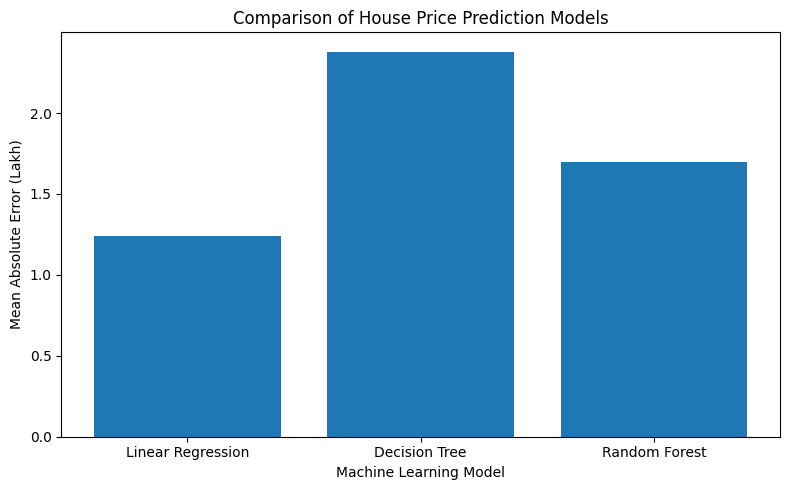

In [5]:

plt.figure(figsize=(8, 5))

plt.bar(results_df["Model"], results_df["MAE (Lakh)"])

plt.title("Comparison of House Price Prediction Models")
plt.xlabel("Machine Learning Model")
plt.ylabel("Mean Absolute Error (Lakh)")
plt.tight_layout()
plt.show()


In [6]:

best_model_name = results_df.loc[
    results_df["MAE (Lakh)"].idxmin(), "Model"
]

print("Best model based on MAE:", best_model_name)
print("\nDay 38 completed successfully!")


Best model based on MAE: Linear Regression

Day 38 completed successfully!
